### 1. Imports and Setup

In [11]:
import os
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


### 2. Load and Preprocess the Dataset
Since downloading directly from Kaggle requires API credentials, we can easily fetch a clean, direct CSV version of the classic IMDB Dataset containing 50,000 reviews for easier execution.

In [12]:
# Download the dataset directly from a public repository
!wget -q https://github.com/Ankit152/IMDB-sentiment-analysis/raw/master/IMDB-Dataset.csv -O IMDB_Dataset.csv

df = pd.read_csv('IMDB_Dataset.csv')
print(df.shape)
display(df.head())

(50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [13]:
# Text cleaning helper
def clean_text(text):
    text = text.lower()
    text = re.sub(r'<br\s*/?>', ' ', text)  # remove HTML line breaks
    text = re.sub(f"[{re.escape(string.punctuation)}]", '', text)  # remove punctuation
    return text

df['review'] = df['review'].apply(clean_text)
df['sentiment'] = df['sentiment'].map({'positive': 1, 'negative': 0})

display(df.head())

,review,sentiment
0,one of the other reviewers has mentioned that ...,1
1,a wonderful little production the filming te...,1
2,i thought this was a wonderful way to spend ti...,1
3,basically theres a family where a little boy j...,0
4,petter matteis love in the time of money is a ...,1


### 3. Build Vocabulary and Tokenize

In [14]:
# Tokenize text and build vocabulary
all_words = []
for review in df['review'].values:
    all_words.extend(review.split())

# Get word counts and keep top 10000 words
word_counts = Counter(all_words)
vocab_size = 10000
most_common_words = word_counts.most_common(vocab_size - 2) # reserved for PAD and UNK

vocab = {word: idx + 2 for idx, (word, _) in enumerate(most_common_words)}
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1

def encode_text(text, max_len=200):
    tokens = text.split()
    encoded = [vocab.get(token, 1) for token in tokens]
    if len(encoded) < max_len:
        encoded = encoded + [0] * (max_len - len(encoded))
    else:
        encoded = encoded[:max_len]
    return encoded

# Encode reviews
max_seq_len = 200
X = np.array([encode_text(review, max_seq_len) for review in df['review'].values])
y = df['sentiment'].values

In [15]:
# Split data into train, validation, and test sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

class IMDBDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = IMDBDataset(X_train, y_train)
val_dataset = IMDBDataset(X_val, y_val)
test_dataset = IMDBDataset(X_test, y_test)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Train size: {len(train_dataset)}, Val size: {len(val_dataset)}, Test size: {len(test_dataset)}")

Train size: 35000, Val size: 7500, Test size: 7500


### 4. Implement PyTorch RNN / LSTM Model

In [16]:
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers=1):
        super(RNNClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        # Using LSTM to mitigate vanishing gradients in vanilla RNN
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=num_layers,
                            batch_first=True, bidirectional=True, dropout=0.3 if num_layers > 1 else 0.0)
        self.fc = nn.Linear(hidden_dim * 2, 1)  # Bidirectional doubles the hidden size
        self.dropout = nn.Dropout(0.3)

    def forward(self, text):
        embedded = self.dropout(self.embedding(text))
        output, (hidden, cell) = self.lstm(embedded)
        # Concatenate final forward and backward hidden states
        hidden = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim = 1)
        out = self.fc(self.dropout(hidden))
        return out.squeeze(1)

### 5. Training Setup

In [17]:
embedding_dim = 128
hidden_dim = 128
num_layers = 2

model = RNNClassifier(vocab_size, embedding_dim, hidden_dim, num_layers).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)

RNNClassifier(
  (embedding): Embedding(10000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (fc): Linear(in_features=256, out_features=1, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
)


In [18]:
def calculate_accuracy(preds, y):
    rounded_preds = torch.round(torch.sigmoid(preds))
    correct = (rounded_preds == y).float()
    return correct.sum() / len(correct)

def train_epoch(model, dataloader, optimizer, criterion):
    model.train()
    epoch_loss = 0
    epoch_acc = 0

    for texts, labels in dataloader:
        texts, labels = texts.to(device), labels.to(device)

        optimizer.zero_grad()
        predictions = model(texts)
        loss = criterion(predictions, labels)
        acc = calculate_accuracy(predictions, labels)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_acc += acc.item()

    return epoch_loss / len(dataloader), epoch_acc / len(dataloader)

def evaluate_epoch(model, dataloader, criterion):
    model.eval()
    epoch_loss = 0
    epoch_acc = 0

    with torch.no_grad():
        for texts, labels in dataloader:
            texts, labels = texts.to(device), labels.to(device)
            predictions = model(texts)
            loss = criterion(predictions, labels)
            acc = calculate_accuracy(predictions, labels)

            epoch_loss += loss.item()
            epoch_acc += acc.item()

    return epoch_loss / len(dataloader), epoch_acc / len(dataloader)

### 6. Start Training Loop

In [19]:
epochs = 5
train_losses, train_accs = [], []
val_losses, val_accs = [], []

for epoch in range(epochs):
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc = evaluate_epoch(model, val_loader, criterion)

    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    print(f"Epoch: {epoch+1:02} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}%")
    print(f"         | Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc*100:.2f}%")

Epoch: 01 | Train Loss: 0.6402 | Train Acc: 62.81%
         | Val Loss:   0.6298 | Val Acc:   66.36%
Epoch: 02 | Train Loss: 0.5611 | Train Acc: 71.62%
         | Val Loss:   0.5419 | Val Acc:   73.98%
Epoch: 03 | Train Loss: 0.4428 | Train Acc: 79.67%
         | Val Loss:   0.3504 | Val Acc:   84.98%
Epoch: 04 | Train Loss: 0.3413 | Train Acc: 85.45%
         | Val Loss:   0.3190 | Val Acc:   86.52%
Epoch: 05 | Train Loss: 0.2990 | Train Acc: 87.54%
         | Val Loss:   0.2983 | Val Acc:   87.71%


### 7. Evaluation & Visualization

In [20]:
# Evaluate on Test Set
test_loss, test_acc = evaluate_epoch(model, test_loader, criterion)
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc*100:.2f}%")

Test Loss: 0.3125 | Test Accuracy: 87.29%


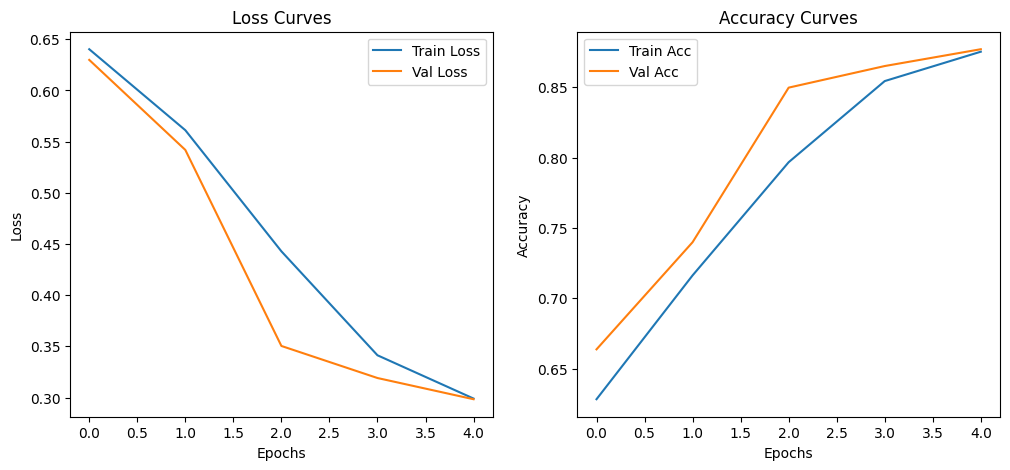

In [21]:
# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(train_losses, label='Train Loss')
ax1.plot(val_losses, label='Val Loss')
ax1.set_title('Loss Curves')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.legend()

ax2.plot(train_accs, label='Train Acc')
ax2.plot(val_accs, label='Val Acc')
ax2.set_title('Accuracy Curves')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.legend()

plt.show()